In [1]:
import ast
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

main_dir = '/home/gap2/Downloads/PPRL-Dev-main/results/faiss/D10/'

In [2]:
df_flat = pd.read_csv(main_dir + 'faiss_flat.csv')
df_flat['index'] = 'flat'
df_hnsw = pd.read_csv(main_dir + 'faiss_hnsw.csv')
df_hnsw['index'] = 'hnsw'
df_lsh = pd.read_csv(main_dir + 'faiss_lsh.csv')
df_lsh['index'] = 'lsh'

In [3]:
result = pd.DataFrame()
dfs = [df_flat, df_hnsw, df_lsh]
for df in dfs:
    result = pd.concat([result, df], ignore_index=True, sort=False)

result['config_dict'] = result['config'].apply(ast.literal_eval)
config_cols = pd.json_normalize(result['config_dict'])
result = result.join(config_cols)
result = result.drop(columns=['config', 'config_dict'])
result

,name,candidate_pairs,top_k,Precision %,Recall %,F1 %,True Positives,False Positives,True Negatives,False Negatives,index,attributes,size,offset,num_hashes,hashing_type,salt,qgrams
0,FAISS FLAT Blocking,23182,1,23.56,24.66,24.10,5462,17720,10729,16686,flat,"[title, starring]",512,0,1,salted_qgrams,,4
1,FAISS FLAT Blocking,46364,2,13.50,28.26,18.27,6258,40106,11525,15890,flat,"[title, starring]",512,0,1,salted_qgrams,,4
2,FAISS FLAT Blocking,69546,3,9.51,29.85,14.42,6611,62935,11878,15537,flat,"[title, starring]",512,0,1,salted_qgrams,,4
3,FAISS FLAT Blocking,92728,4,7.38,30.88,11.91,6840,85888,12107,15308,flat,"[title, starring]",512,0,1,salted_qgrams,,4
4,FAISS FLAT Blocking,115910,5,6.06,31.72,10.18,7025,108885,12292,15123,flat,"[title, starring]",512,0,1,salted_qgrams,,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
475,FAISS LSH Blocking,139092,6,8.01,50.32,13.82,11145,127947,16412,11003,lsh,"[title, starring]",512,0,16,salted_qgrams,,4
476,FAISS LSH Blocking,162274,7,6.96,50.99,12.25,11293,150981,16560,10855,lsh,"[title, starring]",512,0,16,salted_qgrams,,4
477,FAISS LSH Blocking,185456,8,6.15,51.50,10.99,11407,174049,16674,10741,lsh,"[title, starring]",512,0,16,salted_qgrams,,4
478,FAISS LSH Blocking,208638,9,5.52,51.96,9.97,11508,197130,16775,10640,lsh,"[title, starring]",512,0,16,salted_qgrams,,4


In [4]:
result['attributes'].value_counts()

attributes
[title, starring]    480
Name: count, dtype: int64

In [5]:
result['offset'].value_counts()

offset
0    480
Name: count, dtype: int64

In [6]:
result['hashing_type'].value_counts()

hashing_type
salted_qgrams    480
Name: count, dtype: int64

In [7]:
result['qgrams'].value_counts()

qgrams
4    480
Name: count, dtype: int64

In [8]:
result['size'].value_counts()

size
512    480
Name: count, dtype: int64

In [9]:
result['num_hashes'].value_counts()

num_hashes
1     30
2     30
3     30
4     30
5     30
6     30
7     30
8     30
9     30
10    30
11    30
12    30
13    30
14    30
15    30
16    30
Name: count, dtype: int64

In [10]:
valid_rows = result[result['Recall %']>=10]
valid_rows

,name,candidate_pairs,top_k,Precision %,Recall %,F1 %,True Positives,False Positives,True Negatives,False Negatives,index,attributes,size,offset,num_hashes,hashing_type,salt,qgrams
0,FAISS FLAT Blocking,23182,1,23.56,24.66,24.10,5462,17720,10729,16686,flat,"[title, starring]",512,0,1,salted_qgrams,,4
1,FAISS FLAT Blocking,46364,2,13.50,28.26,18.27,6258,40106,11525,15890,flat,"[title, starring]",512,0,1,salted_qgrams,,4
2,FAISS FLAT Blocking,69546,3,9.51,29.85,14.42,6611,62935,11878,15537,flat,"[title, starring]",512,0,1,salted_qgrams,,4
3,FAISS FLAT Blocking,92728,4,7.38,30.88,11.91,6840,85888,12107,15308,flat,"[title, starring]",512,0,1,salted_qgrams,,4
4,FAISS FLAT Blocking,115910,5,6.06,31.72,10.18,7025,108885,12292,15123,flat,"[title, starring]",512,0,1,salted_qgrams,,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
475,FAISS LSH Blocking,139092,6,8.01,50.32,13.82,11145,127947,16412,11003,lsh,"[title, starring]",512,0,16,salted_qgrams,,4
476,FAISS LSH Blocking,162274,7,6.96,50.99,12.25,11293,150981,16560,10855,lsh,"[title, starring]",512,0,16,salted_qgrams,,4
477,FAISS LSH Blocking,185456,8,6.15,51.50,10.99,11407,174049,16674,10741,lsh,"[title, starring]",512,0,16,salted_qgrams,,4
478,FAISS LSH Blocking,208638,9,5.52,51.96,9.97,11508,197130,16775,10640,lsh,"[title, starring]",512,0,16,salted_qgrams,,4


In [11]:
valid_rows['index'].value_counts()

index
flat    160
lsh     160
hnsw      3
Name: count, dtype: int64

In [12]:
max_f1 = valid_rows.loc[valid_rows.groupby(['num_hashes','index'])['F1 %'].idxmax()]
max_f1

,name,candidate_pairs,top_k,Precision %,Recall %,F1 %,True Positives,False Positives,True Negatives,False Negatives,index,attributes,size,offset,num_hashes,hashing_type,salt,qgrams
0,FAISS FLAT Blocking,23182,1,23.56,24.66,24.10,5462,17720,10729,16686,flat,"[title, starring]",512,0,1,salted_qgrams,,4
320,FAISS LSH Blocking,23182,1,23.55,24.65,24.09,5460,17722,10727,16688,lsh,"[title, starring]",512,0,1,salted_qgrams,,4
10,FAISS FLAT Blocking,23182,1,24.52,25.67,25.08,5685,17497,10952,16463,flat,"[title, starring]",512,0,2,salted_qgrams,,4
330,FAISS LSH Blocking,23182,1,24.54,25.69,25.10,5690,17492,10957,16458,lsh,"[title, starring]",512,0,2,salted_qgrams,,4
20,FAISS FLAT Blocking,23182,1,25.31,26.49,25.89,5867,17315,11134,16281,flat,"[title, starring]",512,0,3,salted_qgrams,,4
340,FAISS LSH Blocking,23182,1,25.38,26.56,25.96,5883,17299,11150,16265,lsh,"[title, starring]",512,0,3,salted_qgrams,,4
30,FAISS FLAT Blocking,23182,1,26.30,27.52,26.90,6096,17086,11363,16052,flat,"[title, starring]",512,0,4,salted_qgrams,,4
350,FAISS LSH Blocking,23182,1,26.31,27.54,26.91,6100,17082,11367,16048,lsh,"[title, starring]",512,0,4,salted_qgrams,,4
40,FAISS FLAT Blocking,23182,1,26.74,27.98,27.35,6198,16984,11465,15950,flat,"[title, starring]",512,0,5,salted_qgrams,,4
360,FAISS LSH Blocking,23182,1,26.71,27.96,27.32,6192,16990,11459,15956,lsh,"[title, starring]",512,0,5,salted_qgrams,,4


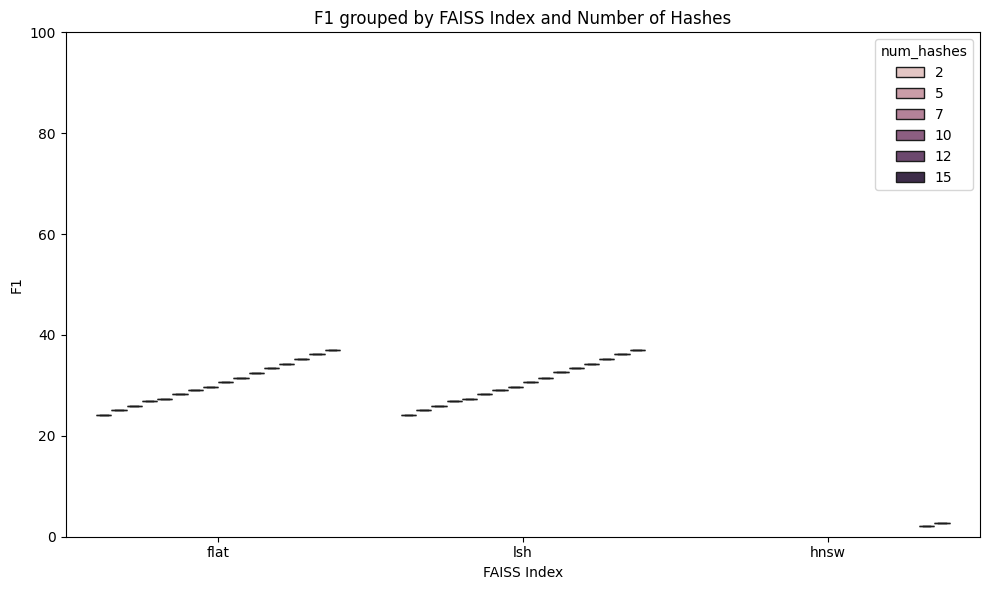

In [13]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=max_f1,
    x="index",
    y="F1 %",
    hue="num_hashes"
)

plt.title("F1 grouped by FAISS Index and Number of Hashes")
plt.xlabel("FAISS Index")
plt.ylabel("F1")
plt.ylim(0, 100) 
plt.legend(title="num_hashes")
plt.tight_layout()
plt.show()

In [14]:
metrics_df = max_f1.melt(
    id_vars=["index", "num_hashes"],
    value_vars=["Precision %", "Recall %", "F1 %"],
    var_name="Metric",
    value_name="Score"
)
metrics_df

,index,num_hashes,Metric,Score
0,flat,1,Precision %,23.56
1,lsh,1,Precision %,23.55
2,flat,2,Precision %,24.52
3,lsh,2,Precision %,24.54
4,flat,3,Precision %,25.31
...,...,...,...,...
97,hnsw,15,F1 %,2.17
98,lsh,15,F1 %,36.24
99,flat,16,F1 %,37.03
100,hnsw,16,F1 %,2.80


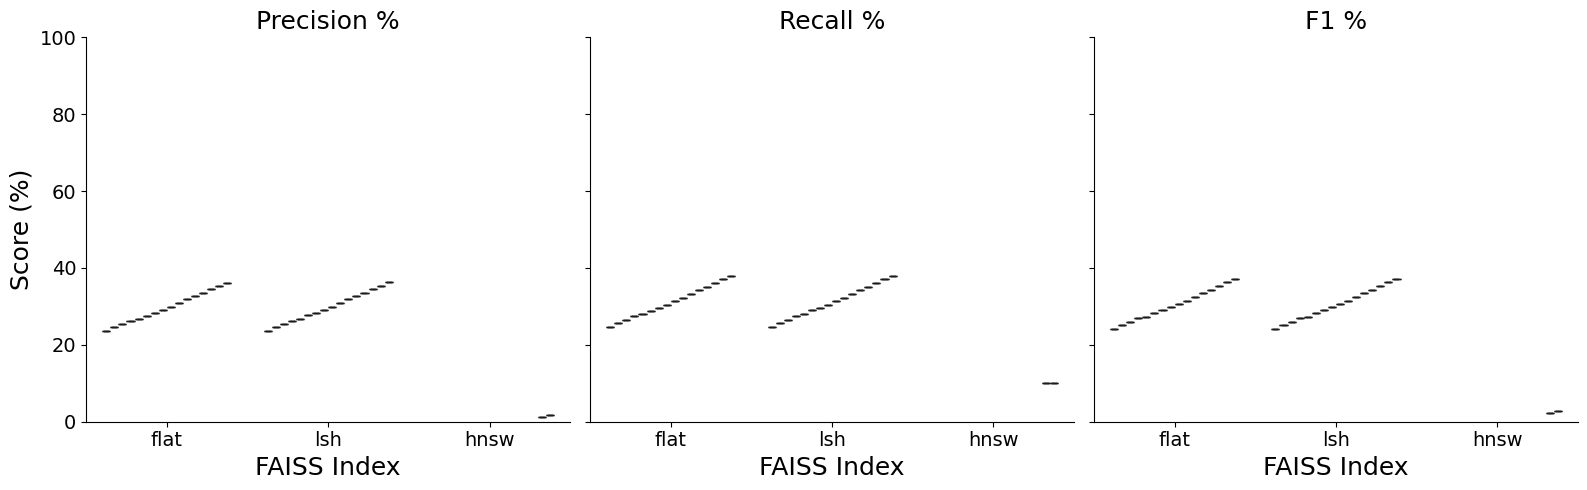

In [15]:
g = sns.catplot(
    data=metrics_df,
    x="index",
    y="Score",
    hue="num_hashes",
    col="Metric",
    kind="box",
    height=5,
    aspect=1,
    fliersize=14  # increase dot size
)
g._legend.remove()
g.set(ylim=(0, 100))
g.set_axis_labels("FAISS Index", "Score (%)", fontsize=18)
g.set_titles("{col_name}", size=18)
for ax in g.axes.flat:
    ax.tick_params(axis='both', labelsize=14)
plt.tight_layout()
plt.show()

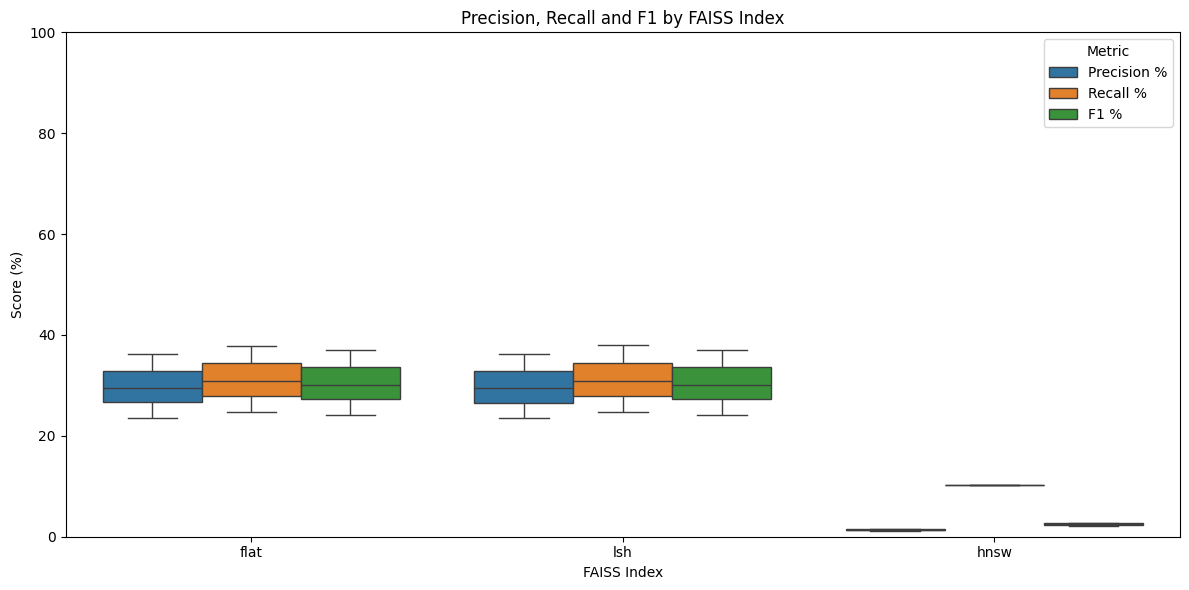

In [16]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=metrics_df,
    x="index",
    y="Score",
    hue="Metric"
)

plt.title("Precision, Recall and F1 by FAISS Index")
plt.xlabel("FAISS Index")
plt.ylabel("Score (%)")
plt.ylim(0, 100) 
plt.legend(title="Metric")
plt.tight_layout()
plt.show()